In [428]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

In [429]:
df = pd.read_csv("../data/raw/Car details v3.csv")

In [430]:
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


### Target Column is: selling_price

```
name -> اسم العربية و نوعها بالضبط
year -> سنة اصدار العربية
selling_price -> سعر العربية (دا الي عايزين نتوقعه)
km_driven -> العربية ماشية قد ايه
fuel -> نوع التفويل
seller_type -> نوع البائع: واحد عادي ولا تاجر
transmission -> اوتوماتيك ولا مانويل
owner -> المالك الكام للعربية
mileage -> العربية بتحرق قد ايه
engine -> كام سي سي
max_power -> قوة العربية
torque -> التورك
seats -> كام راكب
```

In [431]:
df.sample(5)

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
5210,Volkswagen Polo GT TDI,2012,400000,110000,Diesel,Individual,Manual,Second Owner,19.7 kmpl,1598 CC,103.6 bhp,250Nm@ 1500-2500rpm,5.0
7696,Maruti Alto LXi,2010,190000,80000,Petrol,Individual,Manual,First Owner,19.7 kmpl,796 CC,46.3 bhp,62Nm@ 3000rpm,5.0
156,Mercedes-Benz CLA 200 CGI Sport,2018,2550000,18000,Petrol,Dealer,Automatic,First Owner,15.04 kmpl,1991 CC,183 bhp,300Nm@ 1200-4000rpm,5.0
1827,Ford Endeavour 3.0L 4X4 AT,2011,975000,93468,Diesel,Individual,Automatic,Second Owner,11.4 kmpl,2953 CC,153.86 bhp,380Nm@ 2500rpm,7.0
59,Audi A6 2.0 TDI Design Edition,2013,1689999,50000,Diesel,Dealer,Automatic,First Owner,18.53 kmpl,1968 CC,187.74 bhp,400Nm@ 1750-3000rpm,5.0


In [432]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           8128 non-null   str    
 1   year           8128 non-null   int64  
 2   selling_price  8128 non-null   int64  
 3   km_driven      8128 non-null   int64  
 4   fuel           8128 non-null   str    
 5   seller_type    8128 non-null   str    
 6   transmission   8128 non-null   str    
 7   owner          8128 non-null   str    
 8   mileage        7907 non-null   str    
 9   engine         7907 non-null   str    
 10  max_power      7913 non-null   str    
 11  torque         7906 non-null   str    
 12  seats          7907 non-null   float64
dtypes: float64(1), int64(3), str(9)
memory usage: 825.6 KB


In [433]:
df.shape

(8128, 13)

In [434]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
year,8128.0,2013.804011,4.044249,1983.0,2011.0,2015.0,2017.0,2020.0
selling_price,8128.0,638271.807702,806253.403508,29999.0,254999.0,450000.0,675000.0,10000000.0
km_driven,8128.0,69819.510827,56550.554958,1.0,35000.0,60000.0,98000.0,2360457.0
seats,7907.0,5.416719,0.959588,2.0,5.0,5.0,5.0,14.0


In [435]:
df.isnull().sum()

name               0
year               0
selling_price      0
km_driven          0
fuel               0
seller_type        0
transmission       0
owner              0
mileage          221
engine           221
max_power        215
torque           222
seats            221
dtype: int64

In [436]:
df.duplicated().sum()

np.int64(1202)

In [437]:
df.sample(5)

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
895,Tata Indigo CS LX (TDI) BS III,2012,204999,120000,Diesel,Individual,Manual,Second Owner,19.09 kmpl,1396 CC,69 bhp,135Nm@ 2500rpm,5.0
5206,Hyundai Accent Executive CNG,2010,160000,120000,CNG,Individual,Manual,Second Owner,13.2 km/kg,1495 CC,93.7 bhp,124.5Nm@ 3500rpm,5.0
2106,Mahindra XUV500 W9 2WD,2018,1530000,40000,Diesel,Individual,Manual,First Owner,16.0 kmpl,2179 CC,138 bhp,330Nm@ 1600-2800rpm,7.0
5282,Volkswagen CrossPolo 1.5 TDI,2013,350000,70000,Diesel,Individual,Manual,Second Owner,20.14 kmpl,1498 CC,88.5 bhp,230Nm@ 1500-2500rpm,5.0
1751,Maruti Ertiga SHVS ZDI Plus,2017,800000,70000,Diesel,Individual,Manual,First Owner,24.52 kmpl,1248 CC,88.5 bhp,200Nm@ 1750rpm,7.0


### هناخد نسخه نعدل عليها براحتنا

In [438]:
df_clean = df.copy()

In [439]:
df_clean = df_clean.drop_duplicates()

In [440]:
df_clean.duplicated().sum()

np.int64(0)

In [441]:
df_clean.info()

<class 'pandas.DataFrame'>
Index: 6926 entries, 0 to 8125
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           6926 non-null   str    
 1   year           6926 non-null   int64  
 2   selling_price  6926 non-null   int64  
 3   km_driven      6926 non-null   int64  
 4   fuel           6926 non-null   str    
 5   seller_type    6926 non-null   str    
 6   transmission   6926 non-null   str    
 7   owner          6926 non-null   str    
 8   mileage        6718 non-null   str    
 9   engine         6718 non-null   str    
 10  max_power      6721 non-null   str    
 11  torque         6717 non-null   str    
 12  seats          6718 non-null   float64
dtypes: float64(1), int64(3), str(9)
memory usage: 757.5 KB


In [442]:
df_clean.shape

(6926, 13)

In [443]:
df_clean.isnull().sum()

name               0
year               0
selling_price      0
km_driven          0
fuel               0
seller_type        0
transmission       0
owner              0
mileage          208
engine           208
max_power        205
torque           209
seats            208
dtype: int64

In [444]:
df_clean.sample(5)

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
7906,Toyota Innova Crysta 2.8 ZX AT BSIV,2016,1516000,120000,Diesel,Individual,Automatic,First Owner,11.36 kmpl,2755 CC,171.5 bhp,360Nm@ 1200-3400rpm,7.0
7751,Hyundai Venue SX Plus Dual Tone Turbo DCT,2019,1150000,2286,Petrol,Trustmark Dealer,Automatic,First Owner,18.15 kmpl,998 CC,118.35 bhp,171.6Nm@ 1500-4000rpm,5.0
4032,Maruti Swift Dzire VXI,2014,450000,50000,Petrol,Individual,Manual,Second Owner,19.1 kmpl,1197 CC,85.8 bhp,114Nm@ 4000rpm,5.0
6094,Maruti Swift Dzire VDI,2015,615000,60000,Diesel,Individual,Manual,First Owner,26.59 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
4369,Mahindra Scorpio VLS 2.2 mHawk,2008,400000,100000,Diesel,Individual,Manual,Third Owner,12.05 kmpl,2179 CC,120 bhp,290Nm@ 1800-2800rpm,7.0


for columns mileage, engine and max_power they are strings. We will convert it to float and int.

for mileage there is two units: kmpl and km/kg, we will drop the rows with km/kg, because they are only 88 rows of out 6000+ rows

In [445]:
df_clean['mileage'].str.contains('km/kg').sum()

np.int64(87)

deleted all rows that use km/kg and not petrol and diesel to make consistency in data to use only kmpl and petrol and diesel fuel عشان اسهل علي نفسي

In [446]:
df_clean = df_clean[~df_clean['mileage'].str.contains('km/kg', na=False)]
df_clean = df_clean[df_clean['fuel'].isin(['Petrol', 'Diesel'])]

In [447]:
df_clean['mileage'].str.contains('km/kg').sum()

np.int64(0)

In [448]:
print(df_clean['fuel'].value_counts()) 
print(df_clean['mileage'].str.contains('km/kg', na=False).sum())
print(df_clean.shape)    

fuel
Diesel    3755
Petrol    3077
Name: count, dtype: int64
0
(6832, 13)


In [449]:
df_clean['mileage_kmpl'] = df_clean['mileage'].str.extract(r'(\d+\.?\d*)')[0].astype(float)

In [450]:
df_clean['engine_cc'] = df_clean['engine'].str.extract(r'(\d+\.?\d*)')[0].astype(float).astype('Int64')

In [451]:
df_clean['max_power_bhp'] = df_clean['max_power'].str.extract(r'(\d+\.?\d*)')[0].astype(float)

In [452]:
df_clean.sample(5)

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats,mileage_kmpl,engine_cc,max_power_bhp
4687,Maruti Alto 800 VXI BSIV,2015,265000,48000,Petrol,Dealer,Manual,First Owner,24.7 kmpl,796 CC,47.3 bhp,69Nm@ 3500rpm,5.0,24.70,796,47.30
633,Maruti Alto K10 VXI,2019,360000,25000,Petrol,Individual,Manual,First Owner,23.95 kmpl,998 CC,67.05 bhp,90Nm@ 3500rpm,5.0,23.95,998,67.05
1053,Ford Figo Aspire 1.5 TDCi Titanium,2018,793000,30000,Diesel,Individual,Manual,First Owner,25.83 kmpl,1498 CC,99 bhp,215Nm@ 1750-3000rpm,5.0,25.83,1498,99.00
7934,Mahindra TUV 300 T6 Plus,2015,600000,80000,Diesel,Individual,Manual,First Owner,18.49 kmpl,1493 CC,100 bhp,240Nm@ 1600-2800rpm,7.0,18.49,1493,100.00
1887,Maruti Baleno Delta 1.3,2016,700000,78000,Diesel,Individual,Manual,First Owner,27.39 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0,27.39,1248,74.00


In [453]:
df_clean.info()

<class 'pandas.DataFrame'>
Index: 6832 entries, 0 to 8125
Data columns (total 16 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           6832 non-null   str    
 1   year           6832 non-null   int64  
 2   selling_price  6832 non-null   int64  
 3   km_driven      6832 non-null   int64  
 4   fuel           6832 non-null   str    
 5   seller_type    6832 non-null   str    
 6   transmission   6832 non-null   str    
 7   owner          6832 non-null   str    
 8   mileage        6631 non-null   str    
 9   engine         6631 non-null   str    
 10  max_power      6634 non-null   str    
 11  torque         6631 non-null   str    
 12  seats          6631 non-null   float64
 13  mileage_kmpl   6631 non-null   float64
 14  engine_cc      6631 non-null   Int64  
 15  max_power_bhp  6634 non-null   float64
dtypes: Int64(1), float64(3), int64(3), str(9)
memory usage: 914.0 KB


In [454]:
df_clean = df_clean.drop(columns=['mileage', 'engine', 'max_power'])

In [455]:
df_clean.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,torque,seats,mileage_kmpl,engine_cc,max_power_bhp
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,190Nm@ 2000rpm,5.0,23.40,1248,74.00
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,250Nm@ 1500-2500rpm,5.0,21.14,1498,103.52
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,"12.7@ 2,700(kgm@ rpm)",5.0,17.70,1497,78.00
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,22.4 kgm at 1750-2750rpm,5.0,23.00,1396,90.00
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,"11.5@ 4,500(kgm@ rpm)",5.0,16.10,1298,88.20


In [456]:
df_clean.info()

<class 'pandas.DataFrame'>
Index: 6832 entries, 0 to 8125
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           6832 non-null   str    
 1   year           6832 non-null   int64  
 2   selling_price  6832 non-null   int64  
 3   km_driven      6832 non-null   int64  
 4   fuel           6832 non-null   str    
 5   seller_type    6832 non-null   str    
 6   transmission   6832 non-null   str    
 7   owner          6832 non-null   str    
 8   torque         6631 non-null   str    
 9   seats          6631 non-null   float64
 10  mileage_kmpl   6631 non-null   float64
 11  engine_cc      6631 non-null   Int64  
 12  max_power_bhp  6634 non-null   float64
dtypes: Int64(1), float64(3), int64(3), str(6)
memory usage: 753.9 KB


عملت دروب للتورك عشان كان حوار اننا نحوله لي رقم

In [457]:
df_clean = df_clean.drop(columns=['torque'])

In [458]:
df_clean.info()

<class 'pandas.DataFrame'>
Index: 6832 entries, 0 to 8125
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           6832 non-null   str    
 1   year           6832 non-null   int64  
 2   selling_price  6832 non-null   int64  
 3   km_driven      6832 non-null   int64  
 4   fuel           6832 non-null   str    
 5   seller_type    6832 non-null   str    
 6   transmission   6832 non-null   str    
 7   owner          6832 non-null   str    
 8   seats          6631 non-null   float64
 9   mileage_kmpl   6631 non-null   float64
 10  engine_cc      6631 non-null   Int64  
 11  max_power_bhp  6634 non-null   float64
dtypes: Int64(1), float64(3), int64(3), str(5)
memory usage: 700.5 KB


In [459]:
df_clean.sample(5)

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,seats,mileage_kmpl,engine_cc,max_power_bhp
981,Maruti Swift Dzire VXi,2010,240000,143000,Petrol,Individual,Manual,First Owner,5.0,17.50,1298,85.80
1647,Maruti Swift Dzire VDI,2015,470000,110000,Diesel,Individual,Manual,First Owner,5.0,26.59,1248,74.00
2918,Mahindra XUV500 W11 Option BSIV,2018,1700000,15000,Diesel,Individual,Manual,First Owner,7.0,15.10,2179,152.87
4881,Maruti Alto K10 2010-2014 VXI,2010,240000,80000,Petrol,Individual,Manual,Second Owner,5.0,20.92,998,67.10
1741,Maruti Alto K10 2010-2014 VXI,2011,210000,35000,Petrol,Individual,Manual,Second Owner,5.0,20.92,998,67.10


In [460]:
df_clean.describe().T

,count,mean,std,min,25%,50%,75%,max
year,6832.0,2013.433109,4.065728,1983.0,2011.0,2014.0,2017.0,2020.0
selling_price,6832.0,520809.824649,522281.607721,29999.0,250000.0,409999.0,640000.0,10000000.0
km_driven,6832.0,73949.502049,58494.426509,1000.0,39000.0,70000.0,100000.0,2360457.0
seats,6631.0,5.440054,0.988312,2.0,5.0,5.0,5.0,14.0
mileage_kmpl,6631.0,19.434536,4.011447,0.0,16.8,19.4,22.32,42.0
engine_cc,6631.0,1435.693259,494.553445,624.0,1197.0,1248.0,1498.0,3604.0
max_power_bhp,6634.0,88.079131,31.796546,0.0,68.0,81.86,100.0,400.0


In [461]:
df_clean.nunique()

name             2018
year               28
selling_price     670
km_driven         915
fuel                2
seller_type         3
transmission        2
owner               5
seats               9
mileage_kmpl      366
engine_cc         121
max_power_bhp     307
dtype: int64

In name column we will extract only the first word which is the brand only not all the car name to decrease the number of unique values

In [462]:
df_clean['brand'] = df_clean['name'].str.split().str[0]

In [463]:
df_clean.nunique()

name             2018
year               28
selling_price     670
km_driven         915
fuel                2
seller_type         3
transmission        2
owner               5
seats               9
mileage_kmpl      366
engine_cc         121
max_power_bhp     307
brand              32
dtype: int64

In [464]:
# df_clean = df_clean.drop(columns=['name'])

In [465]:
df_clean['car_age'] = 2026 - df_clean['year']

In [466]:
df_clean.sample(5)

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,seats,mileage_kmpl,engine_cc,max_power_bhp,brand,car_age
5480,Hyundai Xcent 1.2 VTVT S,2019,509999,40000,Petrol,Individual,Manual,First Owner,5.0,20.14,1197,81.86,Hyundai,7
1029,Hyundai Creta 1.4 CRDi S Plus,2017,1125000,105000,Diesel,Individual,Manual,First Owner,5.0,21.38,1396,88.70,Hyundai,9
645,Maruti Wagon R VXI BS IV,2012,275000,20000,Petrol,Individual,Manual,First Owner,5.0,18.90,998,67.10,Maruti,14
7388,Maruti Alto K10 2010-2014 VXI,2012,110000,80000,Petrol,Individual,Manual,First Owner,5.0,20.92,998,67.10,Maruti,14
3011,Maruti Alto LX,2011,175000,175000,Petrol,Individual,Manual,Second Owner,5.0,19.70,796,46.30,Maruti,15


### handle missing values
```
since the percentage of missinge values are low we will impute not deletion
seat -> impute with mode
mileage, engine, max power -> impute with median
```

In [467]:
(df_clean.isnull().sum() / len(df_clean)) * 100

name             0.000000
year             0.000000
selling_price    0.000000
km_driven        0.000000
fuel             0.000000
seller_type      0.000000
transmission     0.000000
owner            0.000000
seats            2.942037
mileage_kmpl     2.942037
engine_cc        2.942037
max_power_bhp    2.898126
brand            0.000000
car_age          0.000000
dtype: float64

In [468]:
df_clean['seats'] = df_clean['seats'].fillna(df_clean['seats'].mode()[0])

In [469]:
df_clean.columns

Index(['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type',
       'transmission', 'owner', 'seats', 'mileage_kmpl', 'engine_cc',
       'max_power_bhp', 'brand', 'car_age'],
      dtype='str')

in mileage_kmpl and max_power_bhp there was many zero values for many rows, so we assume they are NaN values to treat it like missing.

In [470]:
df_clean['mileage_kmpl'] = df_clean['mileage_kmpl'].replace(0, np.nan)
df_clean['max_power_bhp'] = df_clean['max_power_bhp'].replace(0, np.nan)

In [471]:
cols = ['mileage_kmpl', 'engine_cc', 'max_power_bhp']

for col in cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

In [472]:
df_clean.isnull().sum()

name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
seats            0
mileage_kmpl     0
engine_cc        0
max_power_bhp    0
brand            0
car_age          0
dtype: int64

### Handlings Outliers

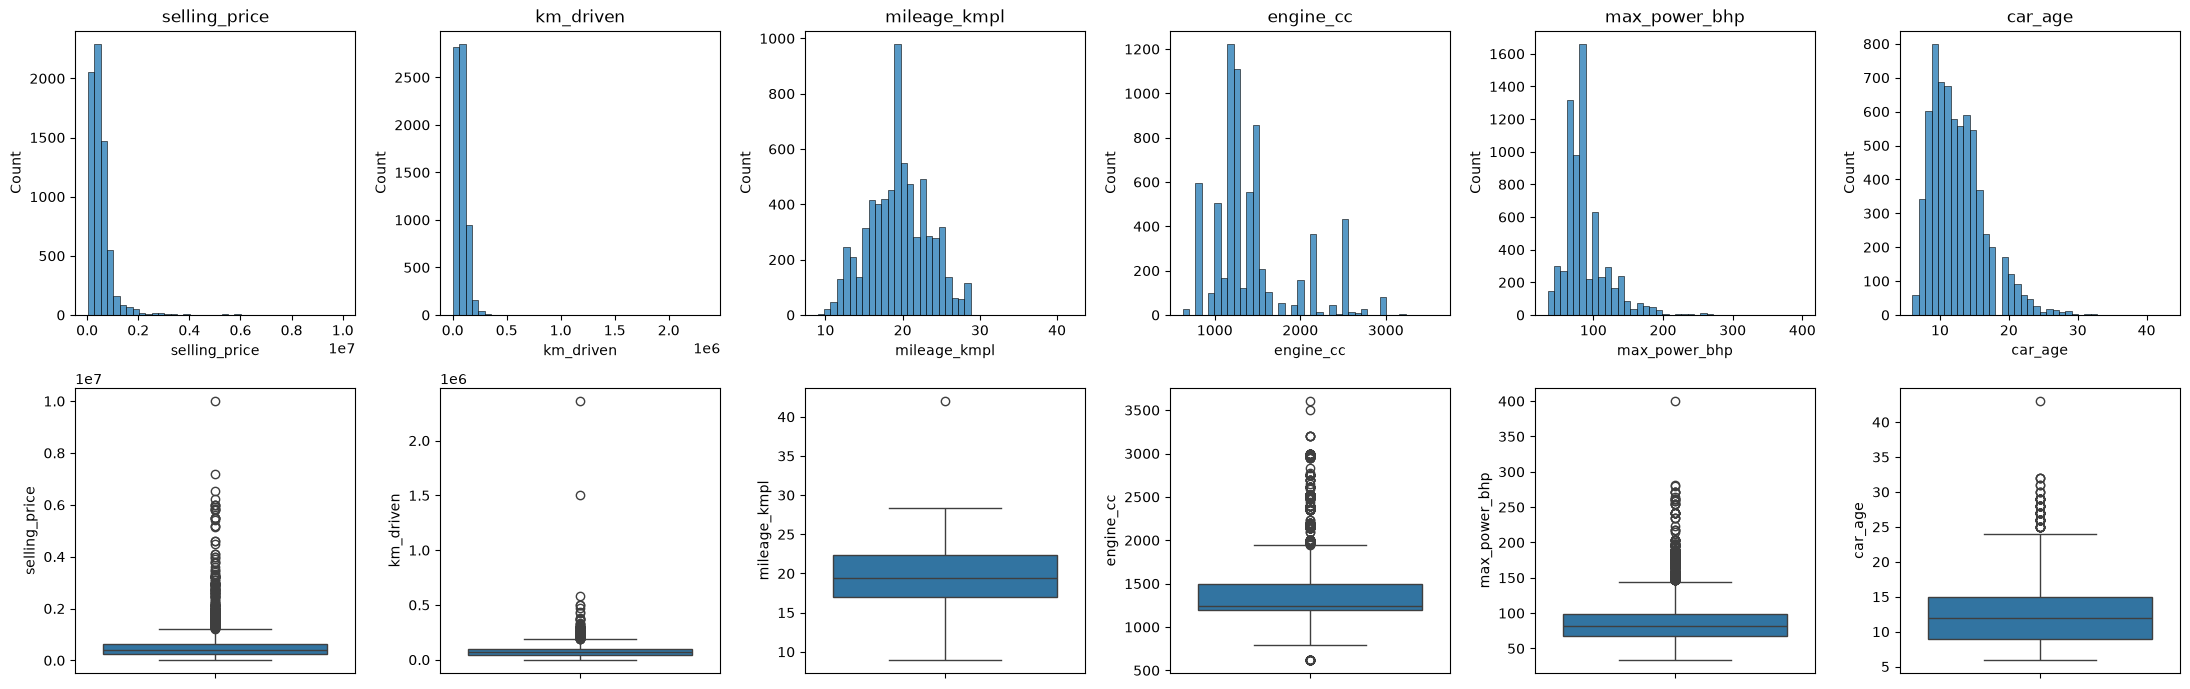

,count,mean,std,min,1%,5%,95%,99%,max
selling_price,6832.0,520809.824649,522281.607721,29999.0,50000.0,100000.0,1200000.0,2737910.0,10000000.0
km_driven,6832.0,73949.502049,58494.426509,1000.0,5000.0,12000.0,156986.25,236966.97,2360457.0
mileage_kmpl,6832.0,19.476114,3.845405,9.0,11.4,12.99,25.8,28.4,42.0
engine_cc,6832.0,1430.171253,488.25447,624.0,796.0,796.0,2499.0,2956.0,3604.0
max_power_bhp,6832.0,87.934838,31.295776,34.2,37.0,47.3,147.8,190.0,400.0
car_age,6832.0,12.566891,4.065728,6.0,7.0,7.0,20.0,25.0,43.0


In [473]:
num_cols = ['selling_price', 'km_driven', 'mileage_kmpl', 'engine_cc', 'max_power_bhp', 'car_age']


fig, axes = plt.subplots(2, len(num_cols), figsize=(22, 7))
for i, col in enumerate(num_cols):
    sns.histplot(df_clean[col], bins=40, ax=axes[0, i])
    sns.boxplot(y=df_clean[col], ax=axes[1, i])
    axes[0, i].set_title(col)
plt.tight_layout()
plt.show()

df_clean[num_cols].describe(percentiles=[.01, .05, .95, .99]).T

In [474]:
for col in num_cols:
    q1, q3 = df_clean[col].quantile([.25, .75])
    iqr = q3 - q1
    mask = (df_clean[col] < q1 - 1.5*iqr) | (df_clean[col] > q3 + 1.5*iqr)
    print(f"{col:15} outliers: {mask.sum():5}  ({mask.mean()*100:.1f}%)  skew: {df_clean[col].skew():.2f}")

selling_price   outliers:   323  (4.7%)  skew: 5.55
km_driven       outliers:   164  (2.4%)  skew: 11.82
mileage_kmpl    outliers:     1  (0.0%)  skew: 0.03
engine_cc       outliers:  1207  (17.7%)  skew: 1.25
max_power_bhp   outliers:   371  (5.4%)  skew: 1.75
car_age         outliers:    74  (1.1%)  skew: 1.00


In [475]:
df_clean.nlargest(10, 'km_driven')[['brand', 'year', 'km_driven', 'selling_price']]

,brand,year,km_driven,selling_price
3486,Hyundai,2007,2360457,550000
1810,Mahindra,2012,1500000,500000
3508,Maruti,2010,577414,194000
3641,Maruti,2011,500000,229999
6673,Toyota,2011,500000,350000
5106,Mahindra,2011,475000,400000
5189,Toyota,2013,440000,750000
5467,Toyota,2010,426000,950000
2272,Mahindra,2010,380000,260000
7102,Toyota,2007,376412,350000


two cars have very hgih km_driven about more than 1 million km, so we will drop them because they are not believable

In [476]:
df_clean = df_clean[df_clean['km_driven'] <= 1_000_000]
print(df_clean.shape)
print(df_clean['km_driven'].skew())

(6830, 14)
1.7041678351679412


In [477]:
df_clean['seats'].value_counts()
df_clean[df_clean['seats'] >= 10]

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,seats,mileage_kmpl,engine_cc,max_power_bhp,brand,car_age
604,Tata Sumo CX 10 Str BSIV,2011,175000,20000,Diesel,Individual,Manual,First Owner,10.0,12.20,1948,68.0,Tata,15
795,Chevrolet Tavera Neo 3 LS 10 Str,2016,409999,60000,Diesel,Individual,Manual,Second Owner,10.0,12.20,1994,105.3,Chevrolet,10
2086,Tata Sumo EX 10/7 Str BSIII,2012,200000,67500,Diesel,Individual,Manual,First Owner,10.0,12.20,1948,68.0,Tata,14
2331,Chevrolet Tavera Neo 3 10 Seats BSIII,2014,600000,110000,Diesel,Individual,Manual,First Owner,10.0,13.58,2499,72.4,Chevrolet,12
3283,Chevrolet Tavera Neo 3 LS 10 Seats BSIII,2015,580000,110000,Diesel,Individual,Manual,Second Owner,10.0,13.58,2499,72.4,Chevrolet,11
3714,Chevrolet Tavera B3 LT L1 10 Seats BSIII,2005,160000,220000,Diesel,Individual,Manual,First Owner,10.0,14.80,2499,80.0,Chevrolet,21
3794,Chevrolet Tavera LS B3 10 Seats BSII,2006,225000,100000,Diesel,Individual,Manual,First Owner,10.0,14.80,2499,80.0,Chevrolet,20
4112,Tata Sumo SE Plus BSII,2000,95000,120000,Diesel,Individual,Manual,Fourth & Above Owner,10.0,12.20,1948,68.0,Tata,26
4182,Chevrolet Tavera B1-10 seats BSII,2010,280000,100000,Diesel,Individual,Manual,Second Owner,10.0,14.80,2499,80.0,Chevrolet,16
4575,Tata Winger Deluxe - Flat Roof (Non-AC),2010,235000,50000,Diesel,Individual,Manual,First Owner,14.0,10.71,1948,90.0,Tata,16


some cars have more than 10 seats but that is reasonable because they are vans and microbus

In [478]:
df_clean.nlargest(10, 'selling_price')[['name', 'year', 'km_driven', 'selling_price']]

,name,year,km_driven,selling_price
170,Volvo XC90 T8 Excellence BSIV,2017,30000,10000000
2938,BMW X7 xDrive 30d DPE,2020,5000,7200000
4952,Audi A6 35 TFSI Matrix,2019,23600,6523000
4950,Audi A6 35 TFSI Matrix,2019,7800,6223000
136,Mercedes-Benz S-Class S 350 CDI,2017,37000,6000000
1071,BMW 6 Series GT 630d Luxury Line,2018,28156,6000000
4766,BMW 6 Series GT 630d Luxury Line,2018,27000,6000000
4951,Audi A6 35 TFSI Matrix,2019,11500,5923000
148,Mercedes-Benz S-Class S 350 CDI,2017,47000,5850000
6258,BMW 6 Series GT 630d Luxury Line,2018,30000,5830000


selling price are reasonable because the first 10 ten are luxury cars so we will keep it

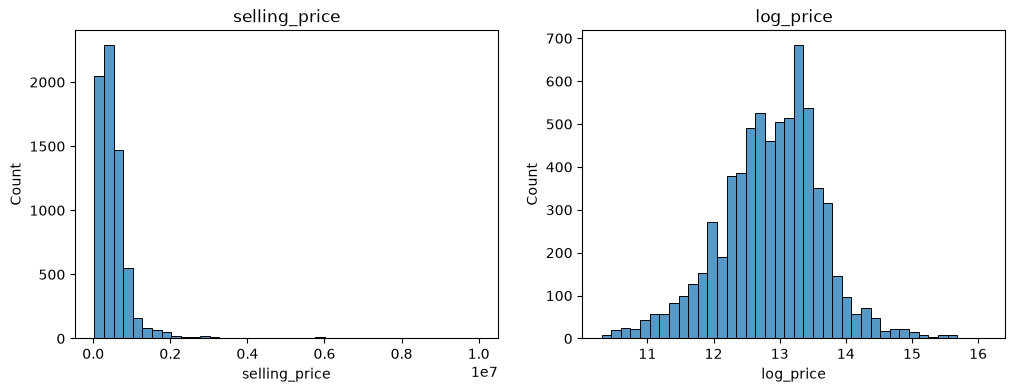

In [479]:
df_clean['log_price'] = np.log1p(df_clean['selling_price'])   # for EDA, you can drop it later
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df_clean['selling_price'], bins=40, ax=ax[0]); ax[0].set_title('selling_price')
sns.histplot(df_clean['log_price'], bins=40, ax=ax[1]);     ax[1].set_title('log_price')
plt.show()

selling_price is heavily right skewed, but log price is symmetric so we recommend using it in modeling.

In [480]:
df_clean.nlargest(10, 'mileage_kmpl')[['name', 'mileage_kmpl', 'km_driven', 'selling_price']]

,name,mileage_kmpl,km_driven,selling_price
170,Volvo XC90 T8 Excellence BSIV,42.0,30000,10000000
214,Maruti Swift Dzire VDI,28.4,50000,700000
400,Maruti Swift Dzire AMT VDI,28.4,19000,750000
434,Maruti Swift Dzire ZDI Plus,28.4,50000,900000
498,Maruti Swift Dzire VDI,28.4,30000,700000
510,Maruti Swift Dzire VDI,28.4,15000,755000
698,Maruti Swift Dzire VDI,28.4,40000,680000
848,Maruti Swift Dzire VDI,28.4,107000,620000
854,Maruti Swift Dzire VDI,28.4,43000,625000
987,Maruti Swift Dzire VDI,28.4,100000,811000


### Categorical features: distributions

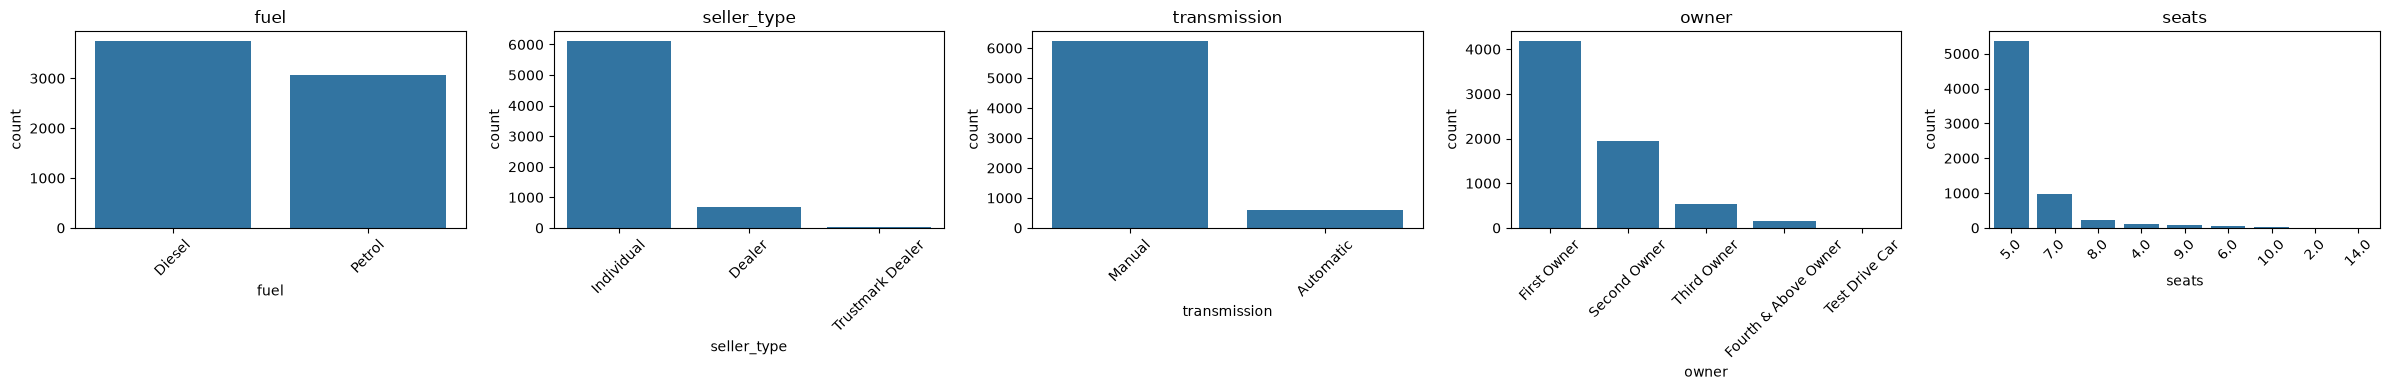

In [481]:
cat_cols = ['fuel', 'seller_type', 'transmission', 'owner', 'seats']

fig, axes = plt.subplots(1, 5, figsize=(24, 4))
for ax, col in zip(axes, cat_cols):
    order = df_clean[col].value_counts().index
    sns.countplot(x=df_clean[col], order=order, ax=ax)
    ax.set_title(col)
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

In [482]:
for col in cat_cols:
    print((df_clean[col].value_counts(normalize=True) * 100).round(1), '\n')

fuel
Diesel    55.0
Petrol    45.0
Name: proportion, dtype: float64 

seller_type
Individual          89.7
Dealer               9.9
Trustmark Dealer     0.4
Name: proportion, dtype: float64 

transmission
Manual       91.4
Automatic     8.6
Name: proportion, dtype: float64 

owner
First Owner             61.3
Second Owner            28.4
Third Owner              7.7
Fourth & Above Owner     2.4
Test Drive Car           0.1
Name: proportion, dtype: float64 

seats
5.0     78.7
7.0     14.1
8.0      3.2
4.0      1.8
9.0      1.1
6.0      0.8
10.0     0.3
2.0      0.0
14.0     0.0
Name: proportion, dtype: float64 



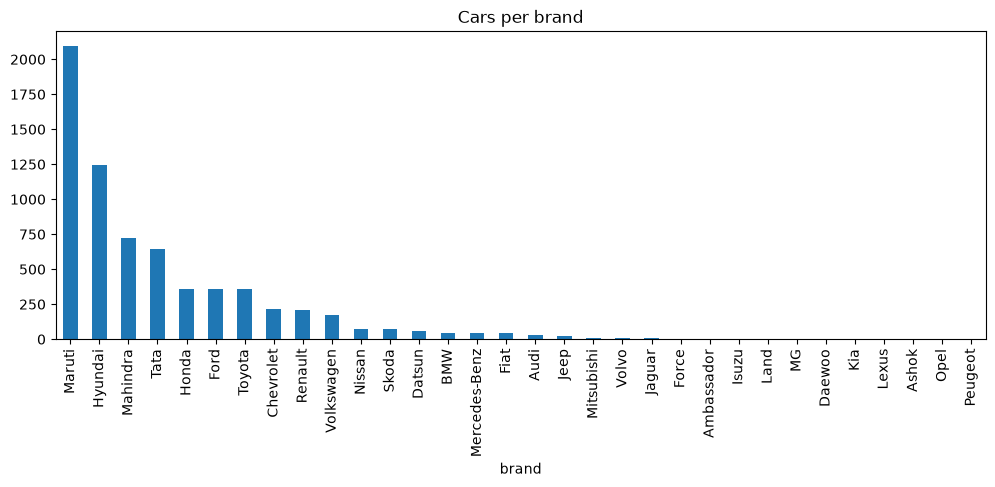

In [483]:
df_clean['brand'].value_counts().plot(kind='bar', figsize=(12, 4), title='Cars per brand')
plt.show()

### Categorical features vs price

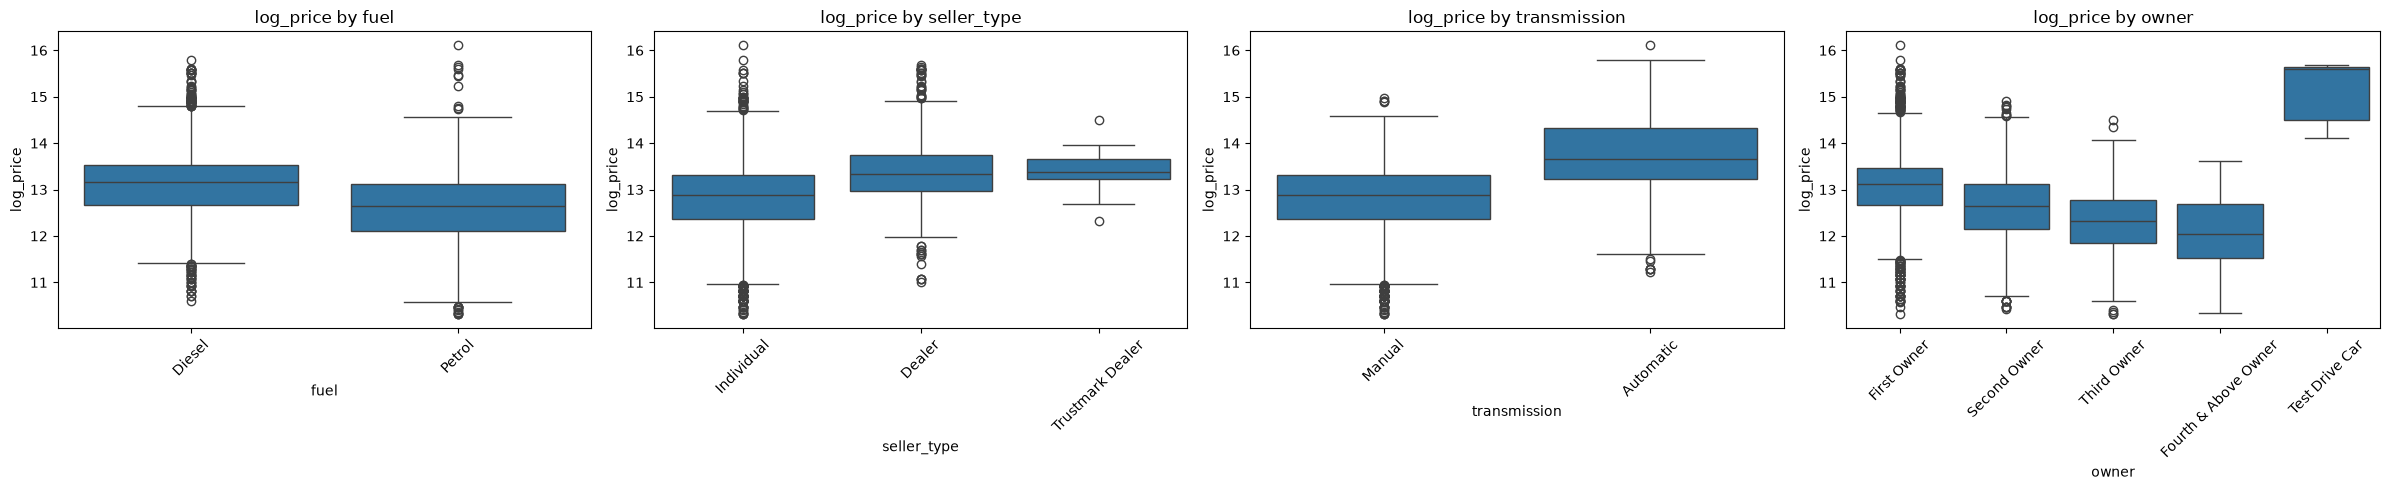

In [484]:
fig, axes = plt.subplots(1, 4, figsize=(24, 5))
for ax, col in zip(axes, ['fuel', 'seller_type', 'transmission', 'owner']):
    sns.boxplot(x=df_clean[col], y=df_clean['log_price'], ax=ax)
    ax.set_title(f'log_price by {col}')
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

In [485]:
for col in ['fuel', 'seller_type', 'transmission', 'owner']:
    print(df_clean.groupby(col)['selling_price'].median().sort_values(), '\n')

fuel
Petrol    310000.0
Diesel    520000.0
Name: selling_price, dtype: float64 

seller_type
Individual          395000.0
Dealer              620000.0
Trustmark Dealer    650000.0
Name: selling_price, dtype: float64 

transmission
Manual       390000.0
Automatic    850000.0
Name: selling_price, dtype: float64 

owner
Fourth & Above Owner     170000.0
Third Owner              225000.0
Second Owner             310000.0
First Owner              500000.0
Test Drive Car          5923000.0
Name: selling_price, dtype: float64 



the highest car in mileage_kmpl is 42, it is reasonable because I seached online and found it

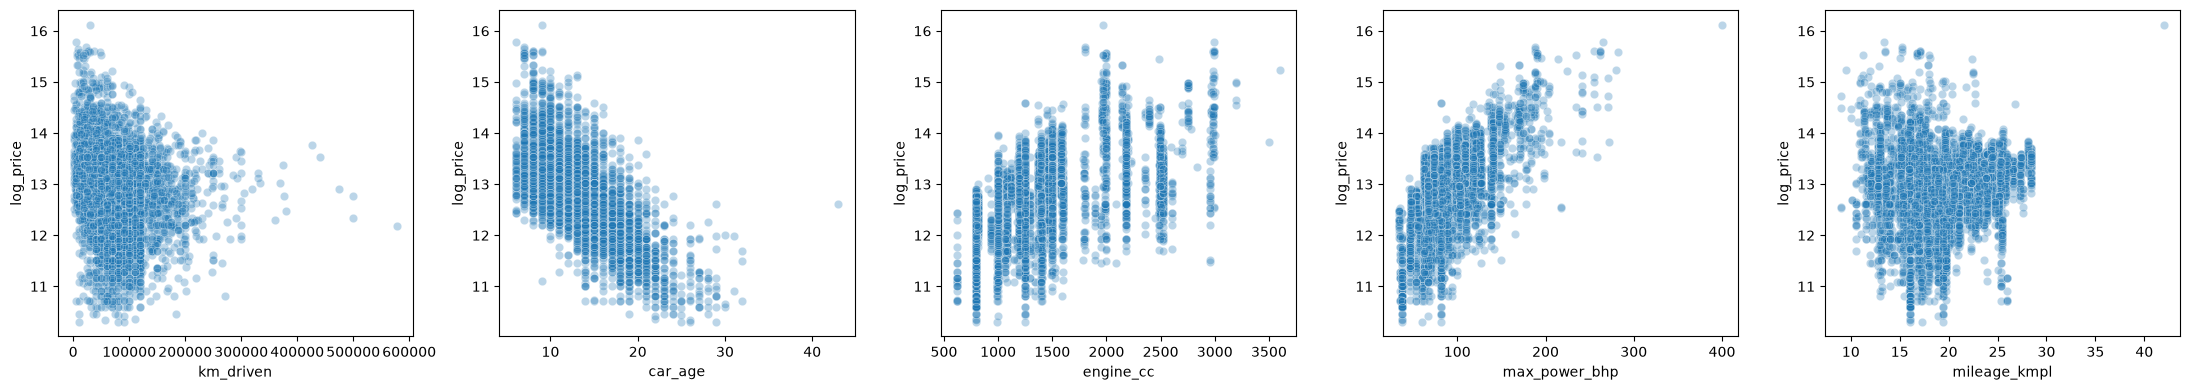

In [486]:
num_cols = ['km_driven', 'car_age', 'engine_cc', 'max_power_bhp', 'mileage_kmpl']
fig, axes = plt.subplots(1, len(num_cols), figsize=(22, 4))
for ax, col in zip(axes, num_cols):
    sns.scatterplot(x=df_clean[col], y=df_clean['log_price'], alpha=0.3, ax=ax)
plt.tight_layout(); plt.show()

### Correlation analysis

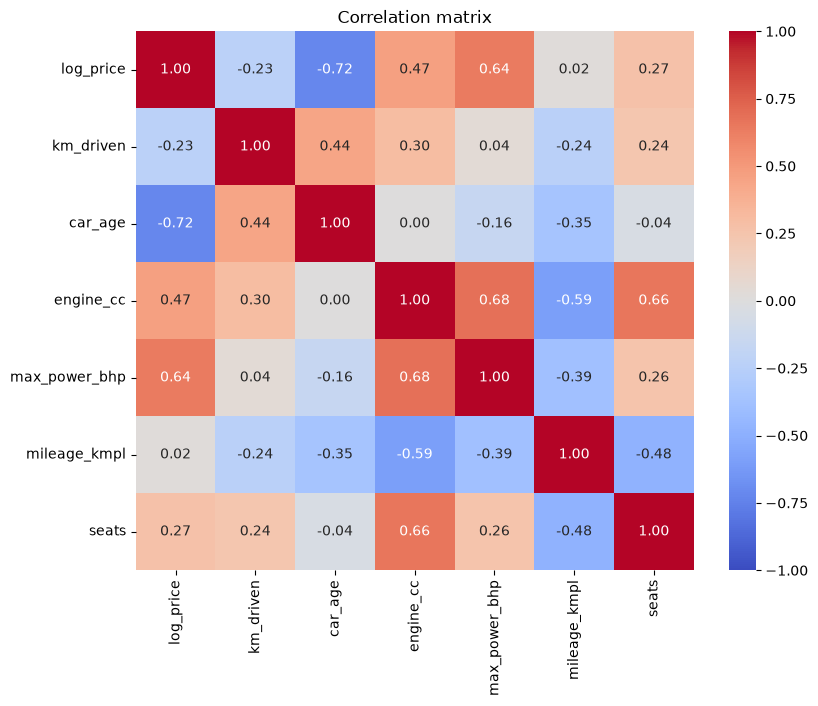

In [487]:
corr_cols = ['log_price', 'km_driven', 'car_age', 'engine_cc', 'max_power_bhp', 'mileage_kmpl', 'seats']
corr = df_clean[corr_cols].astype(float).corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Correlation matrix')
plt.show()

prices fall with car_ages
prices rises with engine_cc and max_power_bhp

In [488]:
df_clean = df_clean.drop(columns=['year', 'name'])

In [489]:
df_clean.info()

<class 'pandas.DataFrame'>
Index: 6830 entries, 0 to 8125
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   selling_price  6830 non-null   int64  
 1   km_driven      6830 non-null   int64  
 2   fuel           6830 non-null   str    
 3   seller_type    6830 non-null   str    
 4   transmission   6830 non-null   str    
 5   owner          6830 non-null   str    
 6   seats          6830 non-null   float64
 7   mileage_kmpl   6830 non-null   float64
 8   engine_cc      6830 non-null   Int64  
 9   max_power_bhp  6830 non-null   float64
 10  brand          6830 non-null   object 
 11  car_age        6830 non-null   int64  
 12  log_price      6830 non-null   float64
dtypes: Int64(1), float64(4), int64(3), object(1), str(4)
memory usage: 753.7+ KB


In [490]:
df_clean.describe().T

,count,mean,std,min,25%,50%,75%,max
selling_price,6830.0,520808.597657,522357.901944,29999.0,250000.0,409999.0,640000.0,10000000.0
km_driven,6830.0,73405.935725,48568.889404,1000.0,39000.0,70000.0,100000.0,577414.0
seats,6830.0,5.42694,0.976443,2.0,5.0,5.0,5.0,14.0
mileage_kmpl,6830.0,19.476883,3.845589,9.0,16.96,19.4,22.32,42.0
engine_cc,6830.0,1430.095754,488.23372,624.0,1197.0,1248.0,1498.0,3604.0
max_power_bhp,6830.0,87.928109,31.293929,34.2,68.0,81.86,99.0,400.0
car_age,6830.0,12.565739,4.065541,6.0,9.0,12.0,15.0,43.0
log_price,6830.0,12.87097,0.76403,10.308953,12.42922,12.923912,13.369225,16.118096


In [491]:
df_clean.sample(5)

,selling_price,km_driven,fuel,seller_type,transmission,owner,seats,mileage_kmpl,engine_cc,max_power_bhp,brand,car_age,log_price
6631,250000,110000,Diesel,Individual,Manual,Second Owner,5.0,18.10,1493,110.00,Hyundai,19,12.429220
1185,300000,80000,Diesel,Individual,Manual,First Owner,5.0,19.40,1248,81.86,Toyota,14,12.611541
4040,114999,120000,Diesel,Individual,Manual,Third Owner,5.0,19.09,1396,69.00,Tata,17,11.652687
7735,75000,29000,Petrol,Individual,Manual,First Owner,4.0,16.10,796,37.00,Maruti,18,11.225257
3743,450000,25000,Diesel,Individual,Manual,First Owner,5.0,23.59,1364,67.04,Toyota,11,13.017005


## Encoding

In [492]:
counts = df_clean['brand'].value_counts()
rare = counts[counts < 10].index 

premium_rare = ['Volvo', 'Jaguar', 'Land', 'Lexus']

df_clean['brand'] = np.where(
    df_clean['brand'].isin(rare),
    np.where(df_clean['brand'].isin(premium_rare), 'Other_Premium', 'Other'),
    df_clean['brand']
)

In [493]:
encoding_cols = ['fuel', 'seller_type', 'transmission', 'brand']

for col in encoding_cols:
    print(f'\n{col}:')
    print(*df_clean[col].unique(), sep='\n')


fuel:
Diesel
Petrol

seller_type:
Individual
Dealer
Trustmark Dealer

transmission:
Manual
Automatic

brand:
Maruti
Skoda
Honda
Hyundai
Toyota
Ford
Renault
Mahindra
Tata
Chevrolet
Fiat
Datsun
Jeep
Mercedes-Benz
Mitsubishi
Audi
Volkswagen
BMW
Nissan
Other_Premium
Other


In [494]:
df_clean = pd.get_dummies(df_clean, columns=encoding_cols, dtype=int, drop_first=True)

In [495]:
df_clean.head()

,selling_price,km_driven,owner,seats,mileage_kmpl,engine_cc,max_power_bhp,car_age,log_price,fuel_Petrol,...,brand_Mercedes-Benz,brand_Mitsubishi,brand_Nissan,brand_Other,brand_Other_Premium,brand_Renault,brand_Skoda,brand_Tata,brand_Toyota,brand_Volkswagen
0,450000,145500,First Owner,5.0,23.40,1248,74.00,12,13.017005,0,...,0,0,0,0,0,0,0,0,0,0
1,370000,120000,Second Owner,5.0,21.14,1498,103.52,12,12.821261,0,...,0,0,0,0,0,0,1,0,0,0
2,158000,140000,Third Owner,5.0,17.70,1497,78.00,20,11.970357,1,...,0,0,0,0,0,0,0,0,0,0
3,225000,127000,First Owner,5.0,23.00,1396,90.00,16,12.323860,0,...,0,0,0,0,0,0,0,0,0,0
4,130000,120000,First Owner,5.0,16.10,1298,88.20,19,11.775297,1,...,0,0,0,0,0,0,0,0,0,0


In [496]:
from sklearn.preprocessing import OrdinalEncoder

ordinal_cols = ['owner']

ordinal_categories = [
    [ 'Test Drive Car', 'First Owner', 'Second Owner', 'Third Owner',
     'Fourth & Above Owner']
]

encoder = OrdinalEncoder(categories=ordinal_categories)

df_clean[ordinal_cols] = encoder.fit_transform(
    df_clean[ordinal_cols]
)

In [497]:
df_clean.sample(5)

,selling_price,km_driven,owner,seats,mileage_kmpl,engine_cc,max_power_bhp,car_age,log_price,fuel_Petrol,...,brand_Mercedes-Benz,brand_Mitsubishi,brand_Nissan,brand_Other,brand_Other_Premium,brand_Renault,brand_Skoda,brand_Tata,brand_Toyota,brand_Volkswagen
1070,750000,15000,1.0,5.0,22.00,1197,81.80,8,13.527830,1,...,0,0,0,0,0,0,0,0,0,0
8071,425000,200000,2.0,7.0,12.80,2494,102.00,16,12.959847,0,...,0,0,0,0,0,0,0,0,1,0
4947,875000,77524,1.0,5.0,22.70,1498,89.84,9,13.681980,0,...,0,0,0,0,0,0,0,0,0,0
912,130000,60000,1.0,5.0,22.30,1248,74.00,14,11.775297,0,...,0,0,0,0,0,0,0,1,0,0
7228,440000,30000,1.0,5.0,20.51,998,67.04,9,12.994532,1,...,0,0,0,0,0,0,0,0,0,0


In [498]:
df_clean.info()

<class 'pandas.DataFrame'>
Index: 6830 entries, 0 to 8125
Data columns (total 33 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   selling_price                 6830 non-null   int64  
 1   km_driven                     6830 non-null   int64  
 2   owner                         6830 non-null   float64
 3   seats                         6830 non-null   float64
 4   mileage_kmpl                  6830 non-null   float64
 5   engine_cc                     6830 non-null   Int64  
 6   max_power_bhp                 6830 non-null   float64
 7   car_age                       6830 non-null   int64  
 8   log_price                     6830 non-null   float64
 9   fuel_Petrol                   6830 non-null   int64  
 10  seller_type_Individual        6830 non-null   int64  
 11  seller_type_Trustmark Dealer  6830 non-null   int64  
 12  transmission_Manual           6830 non-null   int64  
 13  brand_BMW          

In [499]:
df_clean['engine_cc'] = df_clean['engine_cc'].astype(int)

## Save into processed csv

In [500]:
import os

os.makedirs('../data/processed', exist_ok=True)

df_final = df_clean.drop(columns=['log_price'])
df_final.to_csv('../data/processed/car_details_processed.csv', index=False)

print(df_final.shape)
print(df_final.isnull().sum().sum())
print(df_final.select_dtypes(include='object').columns.tolist())

(6830, 32)
0
[]


## Summury of EDA

**Data cleaning decisions**
- Removed 1,202 duplicate rows; parsed mileage, engine and max_power from text to numbers.
- Excluded CNG/LPG cars (mileage in km/kg, too few rows); scope is Petrol and Diesel.
- Treated 0 values in mileage and max_power as missing, then imputed with the median.
- Removed 2 impossible km_driven values (> 1,000,000 km). Kept luxury cars as genuine outliers.
- Dropped torque (inconsistent units); engineered brand and car_age.

**What drives price**
- selling_price (INR) is heavily right-skewed; log transform makes it approximately symmetric.
- Price falls strongly with car_age (r = -0.72) and rises with max_power_bhp (r = 0.64).
- km_driven is weakly related once age is considered; mileage_kmpl shows no clear relationship.
- Automatic, Diesel, Dealer and fewer-owner cars have higher median prices.
- Brand has a large effect on price.

**Issues for modeling**
- engine_cc, max_power_bhp and seats are correlated with each other (multicollinearity).
- Classes are imbalanced (90% Individual sellers, 91% Manual).